In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
#metricas
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
#modelos
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


#csv
df = pd.read_csv("data.csv")
df = df.rename(columns = { "field1":"luz", "field2":"segundos_movimiento", "field3":"dB_promedio", "field4":"ocupacion_real","field5":"ocupacion_estimada", "field6":"dB_max","field7":"seg_sin_deteccion"})
df["created_at"] = pd.to_datetime(df["created_at"])
df = df.sort_values("created_at").reset_index(drop=True)
df = df.drop(columns=["entry_id", "latitude", "longitude", "elevation", "status"])

#separacion X e y
features = ["luz","segundos_movimiento", "dB_promedio", "dB_max","seg_sin_deteccion"]
X = df[features]
y = df["ocupacion_real"]



In [6]:
def analisisDescriptivo(df, features):
  print("\n-------------ANALISIS DESCRIPTIVO-------------\n")
  print(f"\nTotal de registros: {df.shape[0]}")
  print(f"Total de características: {len(features)}")
  print(f"Valores nulos totales: {df[features].isnull().sum().sum()}")
  print(f"Periodo de captura: {df['created_at'].min()}  a  {df['created_at'].max()}")

  #estadisticas generales
  print("\n--- Estadísticas por variable ---\n")
  print(df[features].describe().round(2))

  #balance de clases
  conteo_y = df["ocupacion_real"].value_counts().sort_index()
  porcentaje_y = df["ocupacion_real"].value_counts(normalize=True).sort_index() * 100
  df_descriptivo = pd.DataFrame({'Cantidad': conteo_y, 'Porcentaje (%)': porcentaje_y.round(2)})
  df_descriptivo.index = ["Vacío (0)", "Ocupado (1)"]
  print("\n--- Balance de Clases ---")
  print(df_descriptivo)

  #promedio de cada variable segun ocupacion
  print("\n--- Promedio de cada variable según ocupación ---\n")
  print(df.groupby("ocupacion_real")[features].mean().round(2).rename(index={0: "Vacío", 1: "Ocupado"}))

  #grafica balance de clases
  print("\n\n")
  plt.figure(figsize=(6, 3.5))
  plt.bar(["Vacío (0)", "Ocupado (1)"], conteo_y.values, color=['#2ca02c', '#d62728'])
  plt.title("Distribución de Clases")
  plt.ylabel("Cantidad de Muestras")
  plt.show()
  print("\n\n")

  #histogramas de cada variable separados por clase
  fig, axes = plt.subplots(1, len(features), figsize=(18, 3.5))
  for ax, col in zip(axes, features):
    ax.hist(df[df["ocupacion_real"] == 0][col], bins=20, alpha=0.6, label="Vacío", color='#2ca02c')
    ax.hist(df[df["ocupacion_real"] == 1][col], bins=20, alpha=0.6, label="Ocupado", color='#d62728')
    ax.set_title(col)
  axes[0].legend()
  plt.suptitle("Distribución de variables: Vacío vs Ocupado")
  plt.tight_layout()
  plt.show()
  print("\n\n")

  #serie de tiempo de un dia de ejemplo
  dia = df["created_at"].dt.date.unique()[0]
  df_dia = df[df["created_at"].dt.date == dia]
  fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
  axes[0].plot(df_dia["created_at"], df_dia["luz"]); axes[0].set_ylabel("Luz (lux)")
  axes[1].plot(df_dia["created_at"], df_dia["segundos_movimiento"]); axes[1].set_ylabel("Seg. movimiento")
  axes[2].plot(df_dia["created_at"], df_dia["dB_promedio"]); axes[2].set_ylabel("dB promedio")
  axes[3].step(df_dia["created_at"], df_dia["ocupacion_real"], label="Real")
  axes[3].step(df_dia["created_at"], df_dia["ocupacion_estimada"], label="Regla", linestyle="--")
  axes[3].set_ylabel("Ocupación"); axes[3].legend()
  plt.suptitle(f"Lecturas del día {dia}")
  plt.tight_layout()

In [6]:
def analisisDiagnostico(modelo, X_test, y_test, nombre_modelo):
  print(f"\n-------------ANALISIS DIAGNOSTICO ({nombre_modelo})-------------")

  #analisis de importancia de features por permutacion
  resultado = permutation_importance(modelo, X_test, y_test, n_repeats=10, random_state=7)
  importancias = pd.Series(resultado.importances_mean, index=X_test.columns).sort_values(ascending=False)

  print("\n--- Importancia de las variables ---\n")
  print(importancias.round(4))

  top_grafico = importancias.sort_values(ascending=True)
  plt.figure(figsize=(8, 4))
  plt.barh(top_grafico.index, top_grafico.values, color='#2b5c8f')
  plt.title(f"Importancia por Permutación ({nombre_modelo})")
  plt.xlabel("Pérdida de Accuracy al permutar la variable")
  plt.grid(axis='x', linestyle='--', alpha=0.5)
  plt.tight_layout()
  plt.show()

In [2]:
def visualizarArbol(arbol, features):
  #dibujar arbol para ver reglas aprendidas
  plt.figure(figsize=(18, 7))
  plot_tree(arbol, feature_names=features, class_names=["Vacío", "Ocupado"],
            filled=True, rounded=True, fontsize=9)
  plt.title("Árbol de decisión: umbrales aprendidos")
  plt.show()

In [3]:
def erroresRegla(df_test):
  #donde falla la regla actual del ESP32
  print("\n--- Errores de la regla actual (dB > 50 o movimiento, espera de 120 s) ---")
  fp = ((df_test["ocupacion_estimada"] == 1) & (df_test["ocupacion_real"] == 0)).sum()
  fn = ((df_test["ocupacion_estimada"] == 0) & (df_test["ocupacion_real"] == 1)).sum()
  print(f"Falsos positivos (luz encendida en aula vacía): {fp}")
  print(f"Falsos negativos (apagar luz con gente adentro):  {fn}")

  #segundos sin deteccion cuando el aula SI esta ocupada
  ocupado = df_test[df_test["ocupacion_real"] == 1]["seg_sin_deteccion"]
  print(f"\nCon el aula ocupada, el {(ocupado >= 120).mean()*100:.2f}% de las lecturas "
        f"supera los 120 s sin detección (la regla apagaría)")
  print(f"Máximo tiempo sin detección con el aula ocupada: {ocupado.max()} s")

In [4]:
def analisisPredictivo(y_test, prediccion, nombre_modelo):
  print(f"\n-------------ANALISIS PREDICTIVO ({nombre_modelo})-------------")

  acc = accuracy_score(y_test, prediccion)
  prec = precision_score(y_test, prediccion, pos_label=1)
  rec = recall_score(y_test, prediccion, pos_label=1)
  f1 = f1_score(y_test, prediccion, pos_label=1)

  print(f"\n- Exactitud (Accuracy):          {acc:.4f} ({acc*100:.2f}%)")
  print(f"- Precisión (Ocupado):           {prec:.4f} ({prec*100:.2f}%)")
  print(f"- Sensibilidad/Recall (Ocupado): {rec:.4f} ({rec*100:.2f}%)")
  print(f"- F1-Score (Ocupado):            {f1:.4f}")

  print("\n--- Reporte de Clasificación Completo ---\n")
  print(classification_report(y_test, prediccion, target_names=["Vacío", "Ocupado"]))

  fig, ax = plt.subplots(figsize=(5, 4))
  ConfusionMatrixDisplay.from_predictions(y_test, prediccion, display_labels=["Vacío", "Ocupado"],
                                          cmap='Blues', ax=ax, colorbar=False)
  plt.title(f"Matriz de Confusión: {nombre_modelo}")
  plt.grid(False)
  plt.tight_layout()
  plt.show()

  return acc, prec, rec, f1

In [5]:
def analisisPrescriptivo(modelo, X_muestras, y_muestras):
  print("\n-------------ANALISIS PRESCRIPTIVO-------------\n")

  #probabilidad de que el aula este ocupada
  probabilidades = modelo.predict_proba(X_muestras)
  idx_ocupado = list(modelo.classes_).index(1)

  analisis = []

  for i, (_, fila) in enumerate(X_muestras.iterrows()):
    prob = probabilidades[i][idx_ocupado]

    #toma de decisiones
    #apagar con gente adentro es peor que dejar la luz encendida un rato
    #cuando la probabilidad es intermedia, existe periordo de espera
    if prob >= 0.7:
      accion = "Mantener encendido"
      razon = f"Probabilidad de ocupación del {prob*100:.2f}%."
    elif prob >= 0.3:
      accion = "Esperar antes de apagar"
      razon = f"Probabilidad de ocupación del {prob*100:.2f}%. Caso dudoso, volver a evaluar."
    else:
      accion = "Apagar"
      razon = f"Probabilidad de ocupación del {prob*100:.2f}%. Aula probablemente vacía."

    #si se recomienda apagar y la luz esta encendida, se marca como desperdicio
    if accion == "Apagar" and fila["luz"] > 300:
      razon += " Luz encendida en aula vacía: desperdicio detectado."

    analisis.append({
        "Ocupación real": "Ocupado" if y_muestras.iloc[i] == 1 else "Vacío",
        "Prob. ocupado (%)": round(prob * 100, 2),
        "Acción": accion,
        "Razón": razon
    })

  df_acciones = pd.DataFrame(analisis)
  display(df_acciones)

  print("\n--- Resumen de acciones ---")
  print(df_acciones["Acción"].value_counts())

  return df_acciones

In [13]:
#implementacion
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, shuffle=False)
df_test = df.loc[X_test.index]

#modelo 1 arbol de decision
arbol = DecisionTreeClassifier(max_depth=3, random_state=7).fit(X_train, y_train)
prediccion_arbol = arbol.predict(X_test)

#modelo 2 regresion logistica
logistica = LogisticRegression(max_iter=1000).fit(X_train, y_train)
prediccion_logistica = logistica.predict(X_test)

#regla definida
prediccion_regla = df_test["ocupacion_estimada"]


-------------ANALISIS DESCRIPTIVO-------------


Total de registros: 620
Total de características: 5
Valores nulos totales: 0
Periodo de captura: 2026-11-14 08:10:17-08:00  a  2026-11-21 21:20:53-08:00

--- Estadísticas por variable ---

          luz  segundos_movimiento  dB_promedio  dB_max  seg_sin_deteccion
count  620.00               620.00       620.00  620.00             620.00
mean   303.14                 2.67        48.94   59.03              92.18
std    170.62                 4.32        13.74   19.41             179.09
min      0.18                 0.00        30.94   32.00               1.00
25%    151.64                 0.00        38.31   44.00               1.00
50%    401.59                 0.00        42.06   54.00               7.00
75%    417.08                 5.00        63.33   79.00              77.00
max    441.53                16.00        75.81   95.00             600.00

--- Balance de Clases ---
             Cantidad  Porcentaje (%)
Vacío (0)         303

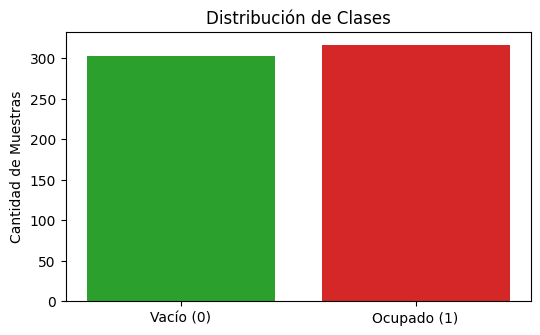

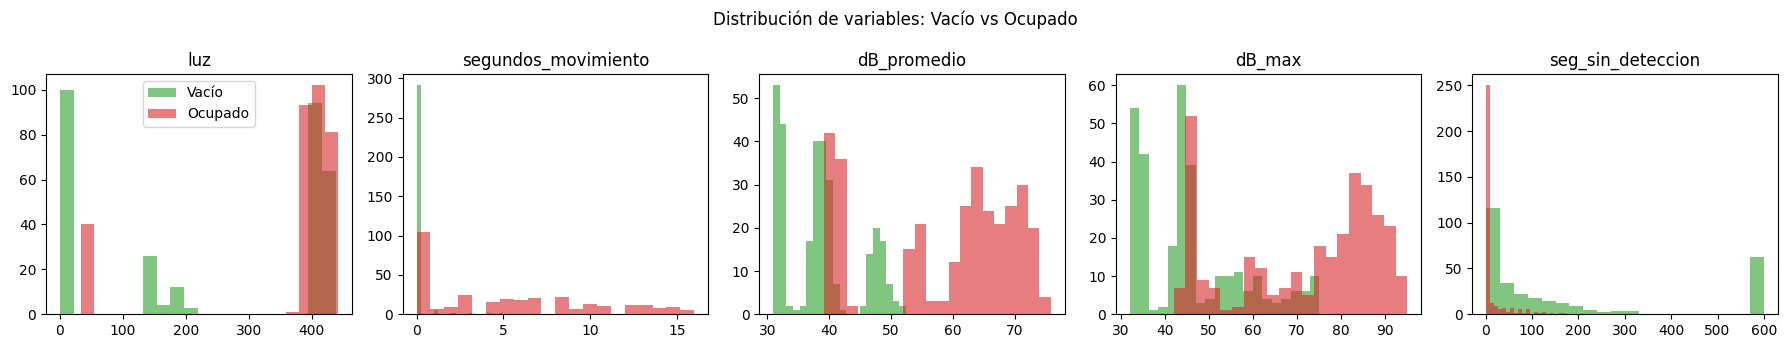

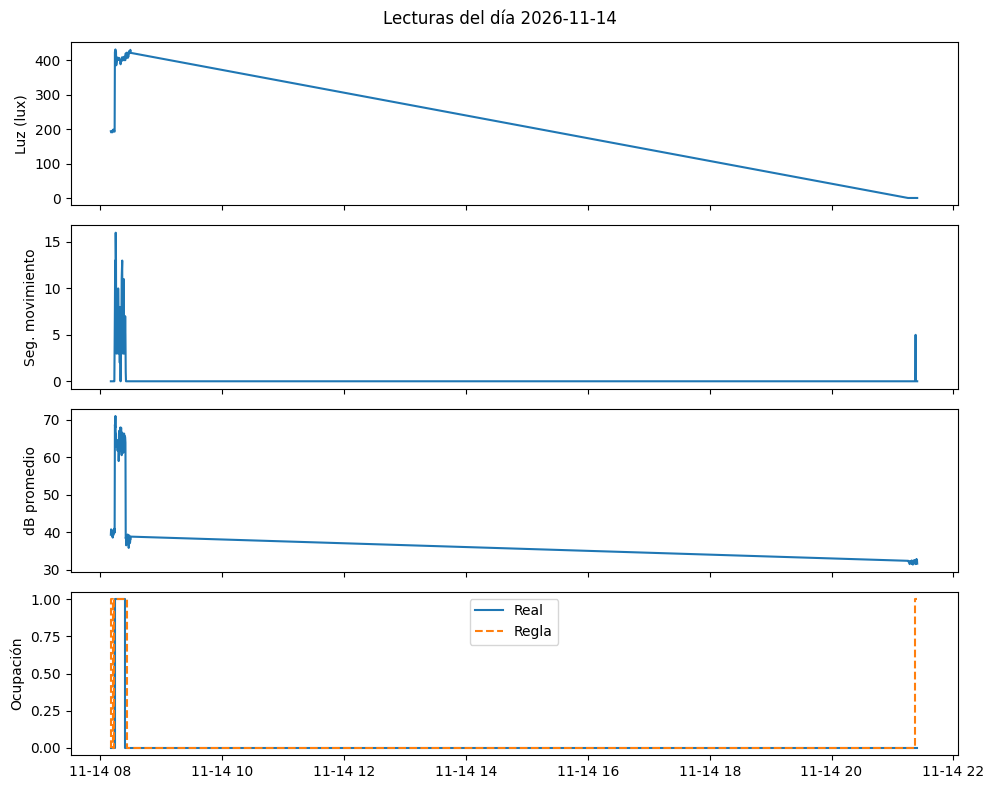

In [10]:
analisisDescriptivo(df, features)

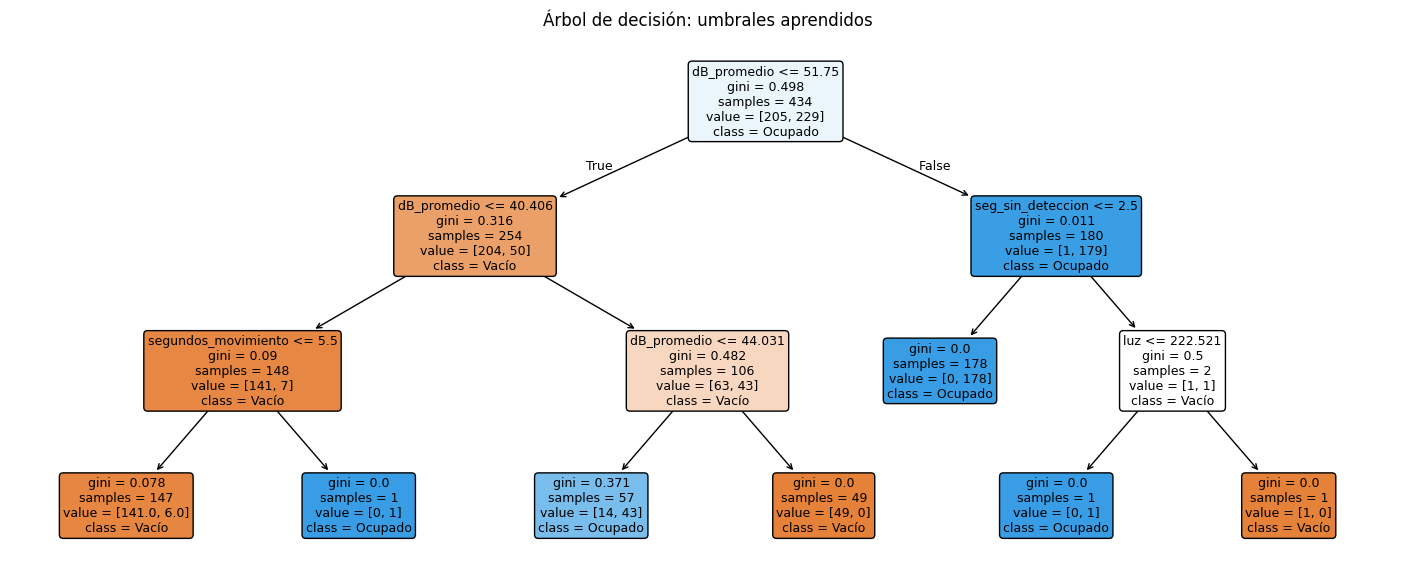


-------------ANALISIS DIAGNOSTICO (Árbol de decisión)-------------

--- Importancia de las variables ---

dB_promedio            0.3215
seg_sin_deteccion      0.2108
segundos_movimiento    0.0914
luz                    0.0022
dB_max                 0.0000
dtype: float64


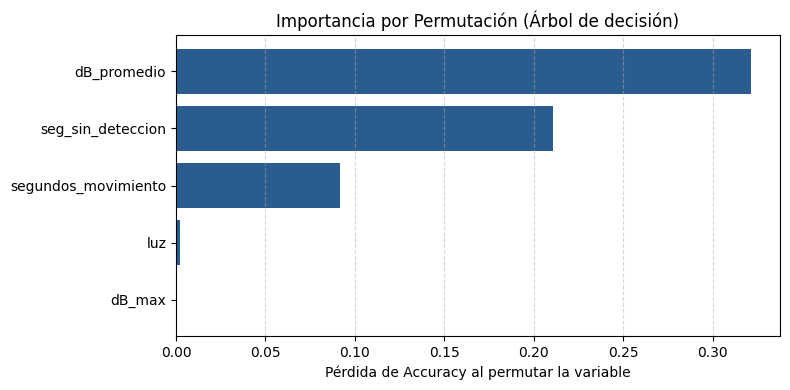


-------------ANALISIS DIAGNOSTICO (Regresión logística)-------------

--- Importancia de las variables ---

dB_promedio            0.4048
segundos_movimiento    0.0720
dB_max                 0.0366
luz                    0.0022
seg_sin_deteccion      0.0022
dtype: float64


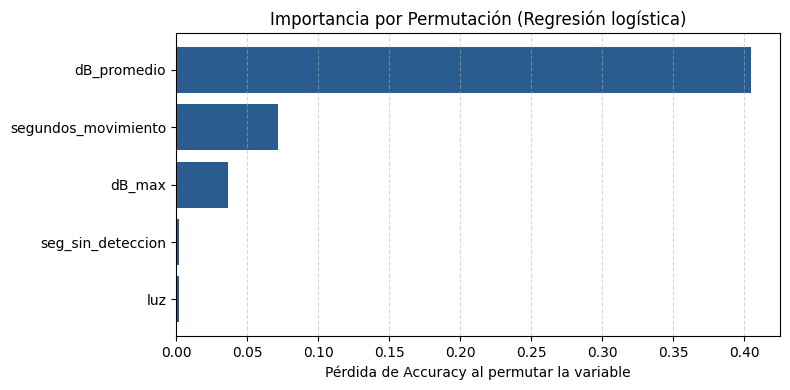


--- Errores de la regla actual (dB > 50 o movimiento, espera de 120 s) ---
Falsos positivos (luz encendida en aula vacía): 53
Falsos negativos (apagar luz con gente adentro):  2

Con el aula ocupada, el 2.27% de las lecturas supera los 120 s sin detección (la regla apagaría)
Máximo tiempo sin detección con el aula ocupada: 127 s


In [14]:
visualizarArbol(arbol, features)
analisisDiagnostico(arbol, X_test, y_test, "Árbol de decisión")
analisisDiagnostico(logistica, X_test, y_test, "Regresión logística")
erroresRegla(df_test)


-------------ANALISIS PREDICTIVO (Regla actual)-------------

- Exactitud (Accuracy):          0.7043 (70.43%)
- Precisión (Ocupado):           0.6187 (61.87%)
- Sensibilidad/Recall (Ocupado): 0.9773 (97.73%)
- F1-Score (Ocupado):            0.7577

--- Reporte de Clasificación Completo ---

              precision    recall  f1-score   support

       Vacío       0.96      0.46      0.62        98
     Ocupado       0.62      0.98      0.76        88

    accuracy                           0.70       186
   macro avg       0.79      0.72      0.69       186
weighted avg       0.80      0.70      0.69       186



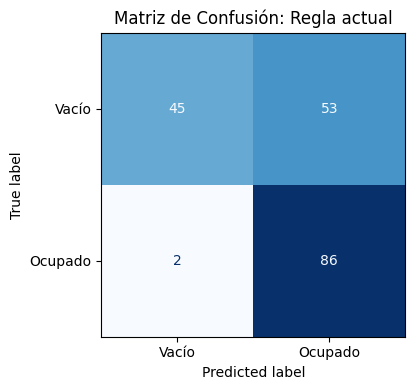


-------------ANALISIS PREDICTIVO (Árbol de decisión)-------------

- Exactitud (Accuracy):          0.9570 (95.70%)
- Precisión (Ocupado):           1.0000 (100.00%)
- Sensibilidad/Recall (Ocupado): 0.9091 (90.91%)
- F1-Score (Ocupado):            0.9524

--- Reporte de Clasificación Completo ---

              precision    recall  f1-score   support

       Vacío       0.92      1.00      0.96        98
     Ocupado       1.00      0.91      0.95        88

    accuracy                           0.96       186
   macro avg       0.96      0.95      0.96       186
weighted avg       0.96      0.96      0.96       186



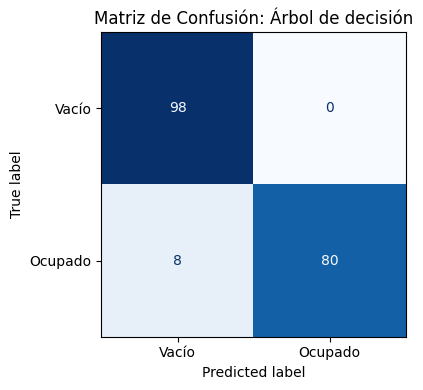


-------------ANALISIS PREDICTIVO (Regresión logística)-------------

- Exactitud (Accuracy):          0.8495 (84.95%)
- Precisión (Ocupado):           0.9412 (94.12%)
- Sensibilidad/Recall (Ocupado): 0.7273 (72.73%)
- F1-Score (Ocupado):            0.8205

--- Reporte de Clasificación Completo ---

              precision    recall  f1-score   support

       Vacío       0.80      0.96      0.87        98
     Ocupado       0.94      0.73      0.82        88

    accuracy                           0.85       186
   macro avg       0.87      0.84      0.85       186
weighted avg       0.87      0.85      0.85       186



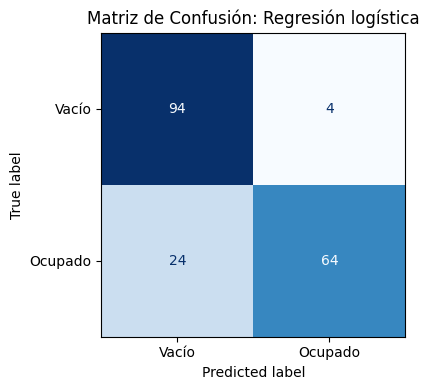


--- Comparación final: regla vs modelos ---



,Accuracy,Precision,Recall,F1
Regla actual (ESP32),0.7043,0.6187,0.9773,0.7577
Árbol de decisión,0.9570,1.0000,0.9091,0.9524
Regresión logística,0.8495,0.9412,0.7273,0.8205


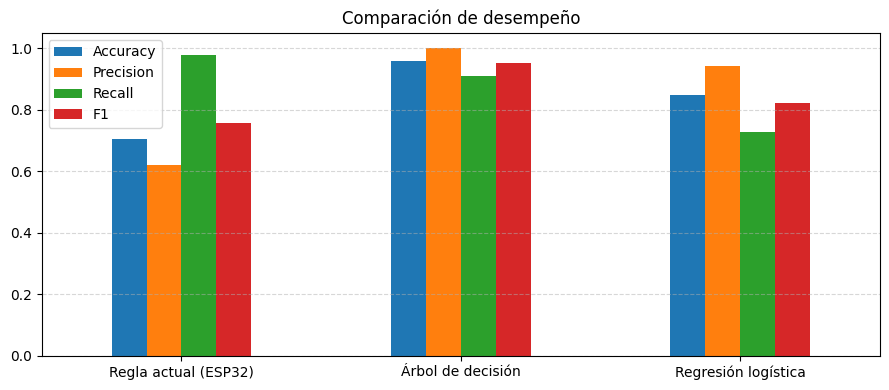

In [11]:
#analisis predictivo
resultados = [
    ("Regla actual (ESP32)", analisisPredictivo(y_test, prediccion_regla, "Regla actual")),
    ("Árbol de decisión", analisisPredictivo(y_test, prediccion_arbol, "Árbol de decisión")),
    ("Regresión logística", analisisPredictivo(y_test, prediccion_logistica, "Regresión logística")),
]

df_comparacion = pd.DataFrame([r[1] for r in resultados], index=[r[0] for r in resultados], columns=["Accuracy", "Precision", "Recall", "F1"]).round(4)
print("\n--- Comparación final: regla vs modelos ---\n")
display(df_comparacion)

df_comparacion.plot(kind="bar", figsize=(9, 4), ylim=(0, 1.05))
plt.title("Comparación de desempeño")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
#analisis prescriptivo
muestra = X_test.sample(n=25, random_state=7)
df_acciones = analisisPrescriptivo(arbol, muestra, y_test.loc[muestra.index])


-------------ANALISIS PRESCRIPTIVO-------------



,Ocupación real,Prob. ocupado (%),Acción,Razón
0,Ocupado,100.00,Mantener encendido,Probabilidad de ocupación del 100.00%.
1,Ocupado,100.00,Mantener encendido,Probabilidad de ocupación del 100.00%.
2,Ocupado,75.44,Mantener encendido,Probabilidad de ocupación del 75.44%.
3,Vacío,4.08,Apagar,Probabilidad de ocupación del 4.08%. Aula prob...
4,Ocupado,100.00,Mantener encendido,Probabilidad de ocupación del 100.00%.
5,Ocupado,100.00,Mantener encendido,Probabilidad de ocupación del 100.00%.
6,Ocupado,4.08,Apagar,Probabilidad de ocupación del 4.08%. Aula prob...
7,Ocupado,100.00,Mantener encendido,Probabilidad de ocupación del 100.00%.
8,Vacío,4.08,Apagar,Probabilidad de ocupación del 4.08%. Aula prob...
9,Ocupado,75.44,Mantener encendido,Probabilidad de ocupación del 75.44%.



--- Resumen de acciones ---
Acción
Apagar                13
Mantener encendido    12
Name: count, dtype: int64
